## 1.Imports and configuration

In [137]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import nltk
from sklearn.preprocessing import LabelEncoder
from nltk.corpus import stopwords
import string
from nltk.stem.porter import PorterStemmer
from collections import Counter
from sklearn.metrics import accuracy_score,precision_score

## 2. Load and validate the dataset
We only retain the label and message columns. The original dataset often contains extra empty columns, so we select the columns we need instead of dropping by fixed column positions.

In [82]:
data=pd.read_csv('spam.csv',encoding='latin1')

In [83]:
data.head()

,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,ham,"Go until jurong point, crazy.. Available only ...",NaN,NaN,NaN
1,ham,Ok lar... Joking wif u oni...,NaN,NaN,NaN
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,NaN,NaN,NaN
3,ham,U dun say so early hor... U c already then say...,NaN,NaN,NaN
4,ham,"Nah I don't think he goes to usf, he lives aro...",NaN,NaN,NaN


In [138]:
data=data.drop(data.columns[2:5],axis=1)
data.rename(columns={'v1':'label','v2':'text'},inplace=True)

In [139]:
encoder=LabelEncoder()
data['label']=encoder.fit_transform(data['label'])

In [140]:
data.head()

,label,text,transformed_text
0,0,"Go until jurong point, crazy.. Available only ...",go jurong point crazi avail bugi n great world...
1,0,Ok lar... Joking wif u oni...,ok lar joke wif u oni
2,1,Free entry in 2 a wkly comp to win FA Cup fina...,free entri 2 wkli comp win fa cup final tkt 21...
3,0,U dun say so early hor... U c already then say...,u dun say earli hor u c alreadi say
4,0,"Nah I don't think he goes to usf, he lives aro...",nah think goe usf live around though


In [143]:
# check for duplicate values
data.duplicated().sum()

np.int64(0)

In [144]:
data=data.drop_duplicates(keep='first')

## 3.Exploratory data analysis (EDA)
Class balance
This chart shows how many legitimate and spam messages are present. Class imbalance matters when interpreting accuracy.

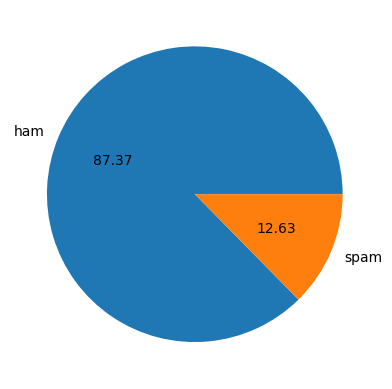

In [145]:
plt.pie(data['label'].value_counts(),labels=['ham','spam'],autopct="%0.2f")
plt.show()

### Message length
Longer messages may have different patterns from short personal messages. Length is used here for exploration only; the classifier below learns from the message text.

In [147]:
#number of characters
data['num_characters']=data['text'].apply(len)
# number of words
data['num_words']=data['text'].apply(lambda x:len(nltk.word_tokenize(x)))
# number of sentences
data['num_sentences']=data['text'].apply(lambda x:len(nltk.sent_tokenize(x))) 

In [148]:
data.head()

,label,text,transformed_text,num_characters,num_words,num_sentences
0,0,"Go until jurong point, crazy.. Available only ...",go jurong point crazi avail bugi n great world...,111,24,2
1,0,Ok lar... Joking wif u oni...,ok lar joke wif u oni,29,8,2
2,1,Free entry in 2 a wkly comp to win FA Cup fina...,free entri 2 wkli comp win fa cup final tkt 21...,155,37,2
3,0,U dun say so early hor... U c already then say...,u dun say earli hor u c alreadi say,49,13,1
4,0,"Nah I don't think he goes to usf, he lives aro...",nah think goe usf live around though,61,15,1


### Below analysis shows the number of characters ,number of words are greter in spam massages as compare to ham massage

<Axes: xlabel='num_characters', ylabel='Count'>

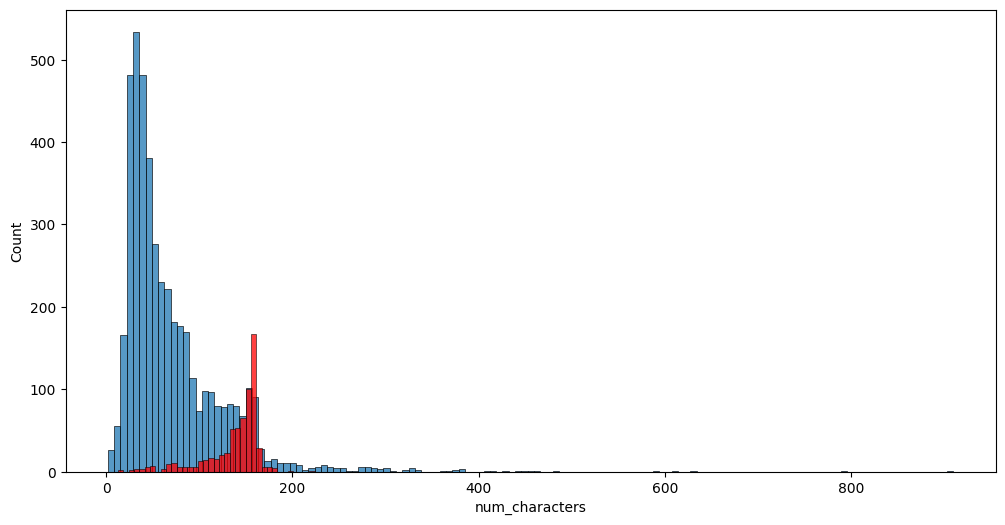

In [149]:
# Count V/S number of charcacters
plt.figure(figsize=(12,6))
sns.histplot(data[data['label']==0]['num_characters']) #for ham
sns.histplot(data[data['label']==1]['num_characters'],color='red') # for spam


<Axes: xlabel='num_words', ylabel='Count'>

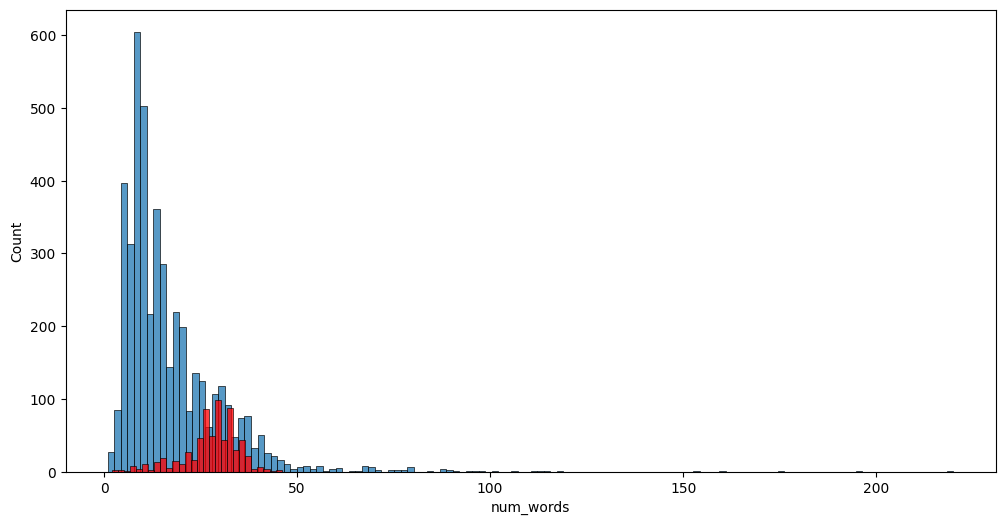

In [150]:
# Count V/S number of words
plt.figure(figsize=(12,6))
sns.histplot(data[data['label']==0]['num_words']) #for ham
sns.histplot(data[data['label']==1]['num_words'],color='red') # for spam


<Axes: xlabel='num_sentences', ylabel='Count'>

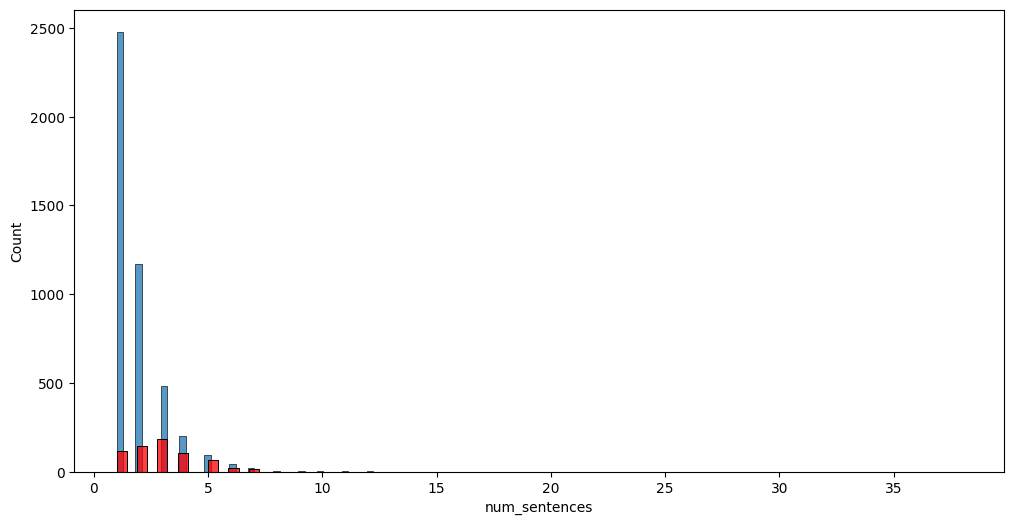

In [106]:
# Count V/S number of sentences
plt.figure(figsize=(12,6))
sns.histplot(data[data['label']==0]['num_sentences']) #for ham
sns.histplot(data[data['label']==1]['num_sentences'],color='red') # for spam


## 4. Data Preprocessing

## 1.Most frequent terms (exploratory)
The simple frequency chart below is based on whitespace-separated words. It is descriptive, not a model feature analysis, and common words can be misleading without context.

In [153]:
ps=PorterStemmer()

In [154]:
def transform_text(text):
    text=text.lower()
    text=nltk.word_tokenize(text)
    y=[]
    for i in text:
        if i.isalnum():
            y.append(i)
    text=y[:]
    y.clear()
    for i in text:
        if i not in stopwords.words('english') and i not in string.punctuation:
            y.append(i)
    text=y[:]
    y.clear()
    for i in text:
        y.append(ps.stem(i))
    return " ".join(y)

In [155]:
data['transformed_text']=data['text'].apply(transform_text)

In [156]:
data.head()

,label,text,transformed_text,num_characters,num_words,num_sentences
0,0,"Go until jurong point, crazy.. Available only ...",go jurong point crazi avail bugi n great world...,111,24,2
1,0,Ok lar... Joking wif u oni...,ok lar joke wif u oni,29,8,2
2,1,Free entry in 2 a wkly comp to win FA Cup fina...,free entri 2 wkli comp win fa cup final tkt 21...,155,37,2
3,0,U dun say so early hor... U c already then say...,u dun say earli hor u c alreadi say,49,13,1
4,0,"Nah I don't think he goes to usf, he lives aro...",nah think goe usf live around though,61,15,1


In [157]:
from wordcloud import WordCloud

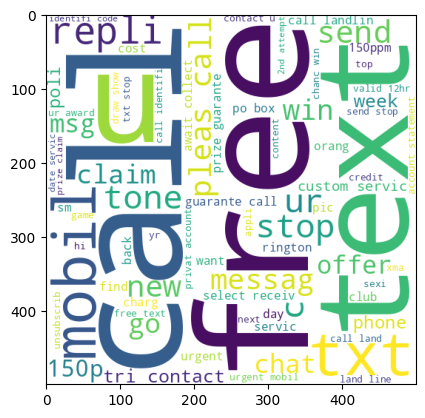

In [158]:
wc=WordCloud(width=500,height=500,min_font_size=10,background_color='white')
spam_wc=wc.generate(data[data['label']==1]['transformed_text'].str.cat(sep=" "))
plt.imshow(spam_wc)

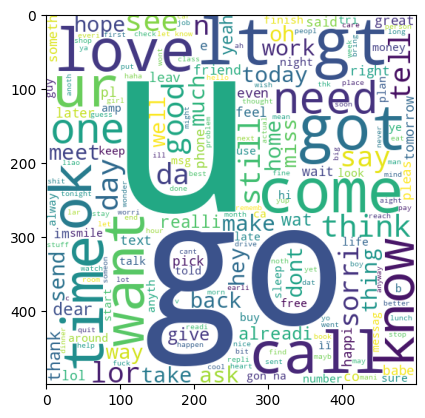

In [159]:
ham_wc=wc.generate(data[data['label']==0]['transformed_text'].str.cat(sep=" "))
plt.imshow(ham_wc)

In [160]:
spam_corpus=[]
for msg in data[data['label']==1]['transformed_text'].tolist():
    for word in msg.split():
        spam_corpus.append(word)

C:\Users\Sumit Kumar\AppData\Local\Temp\ipykernel_22776\1888354310.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=pd.DataFrame(Counter(spam_corpus).most_common(30))[0],y=pd.DataFrame(Counter(spam_corpus).most_common(30))[1],palette='viridis',)


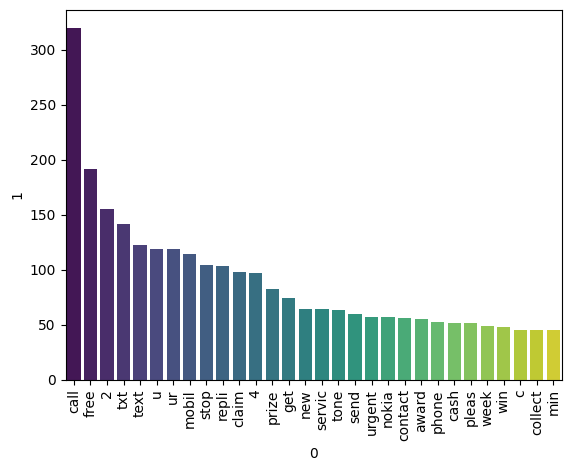

In [161]:
sns.barplot(x=pd.DataFrame(Counter(spam_corpus).most_common(30))[0],y=pd.DataFrame(Counter(spam_corpus).most_common(30))[1],palette='viridis',)
plt.xticks(rotation='vertical')
plt.show()

In [162]:
ham_corpus=[]
for msg in data[data['label']==0]['transformed_text'].tolist():
    for word in msg.split():
        ham_corpus.append(word)

C:\Users\Sumit Kumar\AppData\Local\Temp\ipykernel_22776\1073737347.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=pd.DataFrame(Counter(ham_corpus).most_common(30))[0],y=pd.DataFrame(Counter(ham_corpus).most_common(30))[1],palette='viridis')


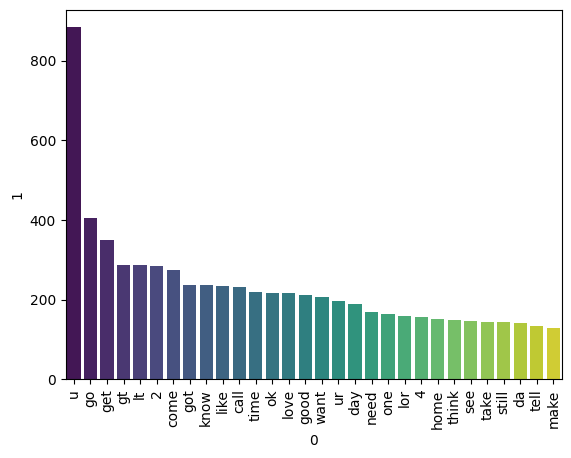

In [163]:
sns.barplot(x=pd.DataFrame(Counter(ham_corpus).most_common(30))[0],y=pd.DataFrame(Counter(ham_corpus).most_common(30))[1],palette='viridis')
plt.xticks(rotation='vertical')
plt.show()

In [164]:
data.head()

,label,text,transformed_text,num_characters,num_words,num_sentences
0,0,"Go until jurong point, crazy.. Available only ...",go jurong point crazi avail bugi n great world...,111,24,2
1,0,Ok lar... Joking wif u oni...,ok lar joke wif u oni,29,8,2
2,1,Free entry in 2 a wkly comp to win FA Cup fina...,free entri 2 wkli comp win fa cup final tkt 21...,155,37,2
3,0,U dun say so early hor... U c already then say...,u dun say earli hor u c alreadi say,49,13,1
4,0,"Nah I don't think he goes to usf, he lives aro...",nah think goe usf live around though,61,15,1


## 5. Train/test split
We split raw messages before fitting TF-IDF. The test set remains unseen during model training and vocabulary construction. Stratification preserves the approximate ham/spam ratio in both sets.

In [165]:
# Naive base algorithm perform best on text data classifiaction
from sklearn.feature_extraction.text import CountVectorizer,TfidfVectorizer
cv=CountVectorizer()
tfidf=TfidfVectorizer(max_features=3000)

In [166]:
y=data['label'].values # gives an array of labels

In [167]:
from sklearn.model_selection import train_test_split
X1_train,X1_test,Y_train,Y_test=train_test_split(data['transformed_text'],y,test_size=0.2,random_state=4,stratify=y)


In [168]:
X_train=tfidf.fit_transform(X1_train)
X_test=tfidf.transform(X1_test)

## 6. Model training and comparison
Each candidate is wrapped in a scikit-learn Pipeline. TF-IDF is fitted only on training messages, and the exact same text transformation is applied during prediction. We compare a few suitable baselines instead of adding many slow models without a clear reason.

In [171]:
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import AdaBoostClassifier
from sklearn.ensemble import BaggingClassifier
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.ensemble import GradientBoostingClassifier
from xgboost import XGBClassifier

In [172]:
svc=SVC(kernel='sigmoid',gamma=1.0)
knc=KNeighborsClassifier()
mnb=MultinomialNB()
dtc=DecisionTreeClassifier(max_depth=5)
lrc=LogisticRegression(solver='liblinear',l1_ratio=1)
rfc=RandomForestClassifier(n_estimators=50,random_state=2)
abc=AdaBoostClassifier(n_estimators=50,random_state=2)
bc=BaggingClassifier(n_estimators=50,random_state=2)
etc=ExtraTreesClassifier(n_estimators=50,random_state=2)
gbdt=GradientBoostingClassifier(n_estimators=50,random_state=2)
xgb=XGBClassifier(n_estimators=50,random_state=2)

In [173]:
clfs={
    'SVC':svc,
    'KN':knc,
    'NB':mnb,
    'DT':dtc,
    'LR':lrc,
    'RF':rfc,
    'AdaBoost':abc,
    'BGC':bc,
    'ETC':etc,
    'GBDT':gbdt,
    'xgb':xgb
}

In [174]:
def train_classifier(clf,X_train,Y_train,X_test,Y_test):
    clf.fit(X_train,Y_train)
    y_pred=clf.predict(X_test)
    accuracy=accuracy_score(Y_test,y_pred)
    precision=precision_score(Y_test,y_pred)

    return accuracy,precision

In [175]:
accuracy_scores=[]
precision_scores=[]
for name,clf in clfs.items():
    current_accuracy,current_precision=train_classifier(clf,X2_train,Y_train,X2_test,Y_test)
    accuracy_scores.append(current_accuracy)
    precision_scores.append(current_precision)

In [176]:
performance_df=pd.DataFrame({'Algorithm':clfs.keys(),'Accuracy':accuracy_scores,'Precision':precision_scores})

In [177]:
performance_df

,Algorithm,Accuracy,Precision
0,SVC,0.970019,0.980769
1,KN,0.912959,0.976744
2,NB,0.969052,1.000000
3,DT,0.932302,0.867470
4,LR,0.954545,0.966667
5,RF,0.967118,0.989899
6,AdaBoost,0.926499,0.831325
7,BGC,0.958414,0.892857
8,ETC,0.975822,0.990741
9,GBDT,0.949710,0.964706


## Key Findings
- Best overall accuracy: Extra Trees Classifier (ETC), with 97.58%.
- Highest precision: Multinomial Naive Bayes (NB), with 100%.
- Strong alternative: Support Vector Classifier (SVC), with 97.00% accuracy and 98.08% precision.
- Lowest accuracy: K-Nearest Neighbors (KN), with 91.30%.
- Lowest precision: AdaBoost, with 83.13%.
- Overall, Multinomial Naive Base provided the strongest balance of accuracy and precision among the evaluated models based on the available metrics.

In [80]:
import pickle
pickle.dump(tfidf,open('vectorizer.pkl','wb'))
pickle.dump(mnb,open('model.pkl','wb'))